# Dataset Diagnostic — Pre-Training Analysis

Run this **before** SSL pretraining. It tells you:

- What the classes actually look like in the graph representation
- Which features separate attacks from benign
- Which attack families are easy vs. hard to distinguish from benign
- **What hyperparameters to use** for the SSL notebook (per dataset)

Outputs a JSON (`dataset_diagnostic.json`) that you can cite in the thesis
as the parameter-selection rationale (Appendix B).

## Cell 1 — Imports and config

In [1]:
import os, json, pickle, gc, warnings
from collections import Counter, defaultdict
import numpy as np
import pandas as pd
from scipy import stats
from sklearn.metrics import pairwise_distances
warnings.filterwarnings('ignore')

# ----- configuration -----
ATTACK_THRESHOLD = 0.10
SEED = 42
np.random.seed(SEED)

DATASETS = {
    'gotham': {
        'dir': 'Gotham_processed_features_10s/graphs',
        'label_merge_fn': None,   # set below
    },
    'nf_ton': {
        'dir': 'NFToNIoT_v3_10s/graphs',
        'label_merge_fn': None,
    },
    'nf_bot': {
        'dir': 'NFBoTIoT_v3_10s/graphs',
        'label_merge_fn': None,
    },
}

EDGE_FEAT_NAMES = ['n_pkts','n_bytes','dur','pkt_size_mean',
                   'flag_syn','flag_ack','flag_fin','flag_rst','flag_psh','proto']
NODE_FEAT_NAMES = ['out_pkts','out_bytes','out_mean_pkt_size',
                   'out_syn_ratio','out_ack_ratio','out_rst_ratio','out_fin_ratio']

def gotham_family_merger(lbl):
    if lbl.startswith('Merlin'): return 'Merlin'
    if lbl.startswith('Mirai'):  return 'Mirai'
    return lbl

DATASETS['gotham']['label_merge_fn'] = gotham_family_merger

print('Config ready.')

Config ready.


## Cell 2 — Helpers

In [2]:
def load_splits(ds_dir):
    out = {}
    for s in ('train', 'val', 'test'):
        with open(os.path.join(ds_dir, f'{s}_graphs.pkl'), 'rb') as f:
            out[s] = pickle.load(f)
    with open(os.path.join(ds_dir, 'norm_stats.json')) as f:
        out['norm'] = json.load(f)
    return out

def dominant_label(g, thr, merge_fn=None):
    names = getattr(g, 'edge_attack_names', None)
    if not names:
        lbl = 'Benign'
    else:
        c = Counter(names); total = sum(c.values())
        atk = {k: v for k, v in c.items()
               if k not in ('Benign','Unknown','unknown','UNKNOWN')}
        if not atk or sum(atk.values()) / max(total,1) < thr:
            lbl = 'Benign'
        else:
            lbl = max(atk, key=atk.get)
    if merge_fn is not None:
        lbl = merge_fn(lbl)
    return lbl

def graph_arrays(g):
    """Return (node_x, edge_attr, n_nodes, n_edges)."""
    x = g.x.cpu().numpy() if hasattr(g.x, 'cpu') else np.asarray(g.x)
    ea = g.edge_attr.cpu().numpy() if hasattr(g.edge_attr, 'cpu') \
         else np.asarray(g.edge_attr)
    if ea.ndim > 2:
        ea = ea.reshape(-1, ea.shape[-1])
    return x, ea, int(x.shape[0]), int(ea.shape[0])

def per_class_edge_agg(graphs, labels):
    """Return dict[class] = (stacked edge attrs, list of edge counts)."""
    buckets = defaultdict(list)
    edge_counts = defaultdict(list)
    for g, l in zip(graphs, labels):
        _, ea, _, ne = graph_arrays(g)
        if ne > 0:
            buckets[l].append(ea)
        edge_counts[l].append(ne)
    return ({c: np.vstack(v) if v else np.zeros((0, len(EDGE_FEAT_NAMES)))
             for c, v in buckets.items()}, dict(edge_counts))

def class_pair_similarity(per_class_edges):
    """Cosine similarity between class means in standardized feature space."""
    classes = sorted(per_class_edges)
    means = []
    for c in classes:
        arr = per_class_edges[c]
        means.append(arr.mean(0) if len(arr) else np.zeros(len(EDGE_FEAT_NAMES)))
    M = np.stack(means)
    Ms = (M - M.mean(0)) / (M.std(0) + 1e-8)
    sim = 1 - pairwise_distances(Ms, metric='cosine')
    return classes, sim

def feature_discriminability(benign_edges, attack_edges):
    """ANOVA F-score per edge feature between Benign and Attack."""
    out = []
    for i, name in enumerate(EDGE_FEAT_NAMES):
        b = benign_edges[:, i] if len(benign_edges) else np.zeros(1)
        a = attack_edges[:, i] if len(attack_edges) else np.zeros(1)
        try:
            f, p = stats.f_oneway(b, a)
        except Exception:
            f, p = 0.0, 1.0
        out.append({'feature': name, 'F': float(f) if np.isfinite(f) else 0.0,
                    'p': float(p) if np.isfinite(p) else 1.0,
                    'benign_mean': float(b.mean()),
                    'attack_mean': float(a.mean())})
    return pd.DataFrame(out).sort_values('F', ascending=False).reset_index(drop=True)

## Cell 3 — Main diagnostic per dataset

In [3]:
DIAGNOSTIC = {}

for ds_name, cfg in DATASETS.items():
    print(f"\n{'#'*100}\n# {ds_name.upper()}\n{'#'*100}")
    if not os.path.isdir(cfg['dir']):
        print(f"  [skip] {cfg['dir']} not found"); continue

    splits = load_splits(cfg['dir'])
    merge_fn = cfg['label_merge_fn']
    thr = ATTACK_THRESHOLD

    # ---------------- 1. Class distributions per split ----------------
    print("\n[1] Class distribution")
    counts = {}
    for s in ('train','val','test'):
        counts[s] = Counter(dominant_label(g, thr, merge_fn) for g in splits[s])
    all_c = sorted(set().union(*[set(c.keys()) for c in counts.values()]))
    print(f"  {'class':<28} {'train':>7} {'val':>7} {'test':>7} "
          f"{'%tot':>7} {'atk?':>5}")
    tot = sum(sum(c.values()) for c in counts.values())
    for c in all_c:
        a, b, cc = counts['train'].get(c,0), counts['val'].get(c,0), counts['test'].get(c,0)
        pct = 100*(a+b+cc)/max(tot,1)
        is_atk = 'no' if c == 'Benign' else 'YES'
        print(f"  {c[:28]:<28} {a:>7} {b:>7} {cc:>7} {pct:>6.2f}% {is_atk:>5}")
    train_atk = sum(v for k,v in counts['train'].items() if k != 'Benign')
    train_ben = counts['train'].get('Benign', 0)
    train_ratio = train_atk / max(train_ben, 1)
    print(f"  attack/benign in train: {train_atk} / {train_ben} = {train_ratio:.3f}")

    # ---------------- 2. Per-class graph size ----------------
    print("\n[2] Per-class graph size (train pool)")
    train_graphs = splits['train']
    train_labels = [dominant_label(g, thr, merge_fn) for g in train_graphs]
    edge_counts = defaultdict(list)
    node_counts = defaultdict(list)
    for g, l in zip(train_graphs, train_labels):
        _, _, nn, ne = graph_arrays(g)
        edge_counts[l].append(ne)
        node_counts[l].append(nn)
    print(f"  {'class':<28} {'n':>6} {'edges_p50':>10} {'edges_p95':>10} "
          f"{'nodes_p50':>10} {'nodes_p95':>10}")
    for c in sorted(edge_counts):
        ec = np.array(edge_counts[c])
        nc = np.array(node_counts[c])
        print(f"  {c[:28]:<28} {len(ec):>6} "
              f"{np.percentile(ec,50):>10.0f} {np.percentile(ec,95):>10.0f} "
              f"{np.percentile(nc,50):>10.0f} {np.percentile(nc,95):>10.0f}")

    all_p95_edges = int(np.percentile(np.concatenate(list(edge_counts.values())), 95))
    max_edges_p95 = int(np.percentile(np.concatenate(list(edge_counts.values())), 99))

    # ---------------- 3. Feature stats per class ----------------
    per_class_edges, _ = per_class_edge_agg(train_graphs, train_labels)
    print("\n[3] Edge-feature means per class")
    hdr = '  ' + f"{'class':<22}" + ''.join(f"{n[:8]:>10}" for n in EDGE_FEAT_NAMES)
    print(hdr)
    for c in sorted(per_class_edges):
        arr = per_class_edges[c]
        if len(arr) == 0: continue
        m = arr.mean(0)
        print(f"  {c[:22]:<22}" + ''.join(f"{m[i]:>10.3f}" for i in range(len(m))))

    # ---------------- 4. Feature discriminability ----------------
    benign_edges = per_class_edges.get('Benign', np.zeros((0, len(EDGE_FEAT_NAMES))))
    atk_edges_list = [v for k,v in per_class_edges.items() if k != 'Benign' and len(v)]
    if atk_edges_list and len(benign_edges):
        all_atk_edges = np.vstack(atk_edges_list)
        disc = feature_discriminability(benign_edges, all_atk_edges)
        print("\n[4] Feature discriminability (Benign vs any-attack, ANOVA F)")
        print(f"  {'feature':<20} {'F':>12} {'p':>12} {'ben_mean':>12} {'atk_mean':>12}")
        for _, r in disc.iterrows():
            print(f"  {r['feature']:<20} {r['F']:>12.2f} {r['p']:>12.2e} "
                  f"{r['benign_mean']:>12.3f} {r['attack_mean']:>12.3f}")
    else:
        disc = pd.DataFrame()
        print("\n[4] Not enough data for feature discriminability")

    # ---------------- 5. Class-pair similarity ----------------
    print("\n[5] Class-pair cosine similarity (feature-space class means)")
    classes, sim = class_pair_similarity(per_class_edges)
    # Print matrix compactly
    short_names = [c[:8] for c in classes]
    header = '  ' + ' '*12 + ''.join(f"{n:>10}" for n in short_names)
    print(header)
    for i, c in enumerate(classes):
        row = '  ' + f"{c[:12]:<12}" + ''.join(f"{sim[i,j]:>10.3f}" for j in range(len(classes)))
        print(row)

    # What is most Benign-like? (attack family most similar to Benign)
    if 'Benign' in classes:
        b_idx = classes.index('Benign')
        bsim = [(classes[j], sim[b_idx, j]) for j in range(len(classes)) if j != b_idx]
        bsim.sort(key=lambda x: -x[1])
        print(f"\n  Most Benign-like attack family: {bsim[0][0]}  (sim={bsim[0][1]:.3f})")
        print(f"  Least Benign-like attack family: {bsim[-1][0]}  (sim={bsim[-1][1]:.3f})")
        hardest = bsim[0][0]
    else:
        hardest = None

    # ---------------- 6. Attack prevalence ----------------
    test_atk_ratio = sum(v for k,v in counts['test'].items() if k != 'Benign') \
                     / max(sum(counts['test'].values()), 1)
    val_atk_ratio  = sum(v for k,v in counts['val'].items() if k != 'Benign') \
                     / max(sum(counts['val'].values()), 1)

    # ---------------- 7. Recommendations ----------------
    # Edge cap: 3x p95 of the largest class, rounded up to nearest 500
    max_class_p95 = max(np.percentile(np.array(ec), 95) for ec in edge_counts.values() if len(ec))
    rec_max_edges_ssl = int(np.ceil(1.3 * max_class_p95 / 500.0) * 500)
    rec_max_edges_ssl = max(2000, min(rec_max_edges_ssl, 20000))

    # Batch size: base 64, scaled down if heavy imbalance
    n_train = sum(counts['train'].values())
    if n_train < 2000:      base_bs = 32
    elif n_train < 5000:    base_bs = 64
    elif n_train < 15000:   base_bs = 96
    else:                   base_bs = 128
    # Reduce further if benign severely underrepresented
    if train_ratio > 5.0:
        base_bs = max(32, base_bs // 2)

    # Augmentation strength: if classes are similar to Benign, augment harder
    aug_strength = 'moderate' if (hardest and sim[classes.index('Benign'), classes.index(hardest)] < 0.7) else 'strong'
    edge_drop = 0.15 if aug_strength == 'moderate' else 0.25
    feat_mask = 0.25 if aug_strength == 'moderate' else 0.35

    # Threshold rule: F1-optimal if attack prevalence is high, else cost-weighted
    if test_atk_ratio > 0.4:
        thr_rule = 'f1_optimal'
    else:
        thr_rule = 'cost_weighted(fn=4x)'

    # Balanced sampler: use if train_ratio far from test_ratio
    test_ratio_benign = 1.0 - test_atk_ratio
    train_ratio_benign = train_ben / max(n_train, 1)
    imbalance_gap = abs(train_ratio_benign - test_ratio_benign)
    use_balanced = bool(imbalance_gap > 0.10)

    print(f"\n[6] Attack prevalence")
    print(f"  train attack ratio : {train_atk/(train_atk+train_ben):.3f}")
    print(f"  val   attack ratio : {val_atk_ratio:.3f}")
    print(f"  test  attack ratio : {test_atk_ratio:.3f}")
    print(f"  train/test benign gap: {imbalance_gap:.3f}")

    print(f"\n[7] Recommendations for SSL training")
    print(f"  MAX_EDGES_SSL         : {rec_max_edges_ssl}")
    print(f"  BATCH_SIZE            : {base_bs}")
    print(f"  USE_BALANCED_SAMPLER  : {use_balanced}")
    print(f"  augmentation strength : {aug_strength}")
    print(f"    EDGE_DROPOUT        : {edge_drop}")
    print(f"    FEATURE_MASK        : {feat_mask}")
    print(f"  threshold rule        : {thr_rule}")
    if hardest is not None:
        print(f"  hardest attack family : {hardest}")

    DIAGNOSTIC[ds_name] = {
        'class_counts': {s: dict(counts[s]) for s in ('train','val','test')},
        'train_attack_ratio': train_atk / max(train_atk+train_ben, 1),
        'test_attack_ratio':  float(test_atk_ratio),
        'benign_train_val_ratio_gap': float(imbalance_gap),
        'edge_p95_all': all_p95_edges,
        'edge_p99_all': max_edges_p95,
        'hardest_attack_family': hardest,
        'feature_discriminability': disc.to_dict(orient='records') if len(disc) else [],
        'recommended': {
            'max_edges_ssl': rec_max_edges_ssl,
            'batch_size': base_bs,
            'use_balanced_sampler': use_balanced,
            'augmentation_strength': aug_strength,
            'edge_dropout': edge_drop,
            'feature_mask': feat_mask,
            'threshold_rule': thr_rule,
        }
    }
    del splits; gc.collect()

with open('dataset_diagnostic.json', 'w') as f:
    json.dump(DIAGNOSTIC, f, indent=2)
print(f"\n\nSaved dataset_diagnostic.json")


####################################################################################################
# GOTHAM
####################################################################################################

[1] Class distribution
  class                          train     val    test    %tot  atk?
  Benign                          1925     345     419  70.04%    no
  CoAP Amplification                 0       0       2   0.05%   YES
  Merlin                           266      63      63  10.21%   YES
  Mirai                            274      78      63  10.81%   YES
  TCP Scan                          53      30       9   2.40%   YES
  Telnet Brute Force                21      22      12   1.43%   YES
  UDP Scan                         141      30      23   5.05%   YES
  attack/benign in train: 755 / 1925 = 0.392

[2] Per-class graph size (train pool)
  class                             n  edges_p50  edges_p95  nodes_p50  nodes_p95
  Benign                         1925         

## Cell 4 — Cross-dataset summary table

In [4]:
print(f"{'='*110}")
print(f"{'SUMMARY':^110}")
print(f"{'='*110}")

print(f"\n{'dataset':<10} {'#train':>8} {'atk% train':>11} {'atk% test':>10} "
      f"{'gap':>6} {'hardest atk':<20}")
for ds, r in DIAGNOSTIC.items():
    n_tr = sum(r['class_counts']['train'].values())
    print(f"{ds:<10} {n_tr:>8} {r['train_attack_ratio']*100:>10.1f}% "
          f"{r['test_attack_ratio']*100:>9.1f}% "
          f"{r['benign_train_val_ratio_gap']:>6.3f} "
          f"{(r['hardest_attack_family'] or 'n/a'):<20}")

print(f"\n{'dataset':<10} {'max_e_ssl':>10} {'bs':>5} {'bal_samp':>9} "
      f"{'aug':>9} {'e_drop':>7} {'f_mask':>7} {'thr_rule':<22}")
for ds, r in DIAGNOSTIC.items():
    rec = r['recommended']
    print(f"{ds:<10} {rec['max_edges_ssl']:>10} {rec['batch_size']:>5} "
          f"{str(rec['use_balanced_sampler']):>9} "
          f"{rec['augmentation_strength']:>9} "
          f"{rec['edge_dropout']:>7.2f} {rec['feature_mask']:>7.2f} "
          f"{rec['threshold_rule']:<22}")

print(f"\n{'='*110}")
print("Copy the max_edges_ssl, bs, aug values into the SSL notebook's config cells.")

                                                   SUMMARY                                                    

dataset      #train  atk% train  atk% test    gap hardest atk         
gotham         2680       28.2%      29.1%  0.009 Telnet Brute Force  
nf_ton        22643       80.1%      79.0%  0.011 scanning            
nf_bot         5013       88.3%      65.5%  0.227 Reconnaissance      

dataset     max_e_ssl    bs  bal_samp       aug  e_drop  f_mask thr_rule              
gotham          20000    64     False  moderate    0.15    0.25 cost_weighted(fn=4x)  
nf_ton          20000   128     False    strong    0.25    0.35 f1_optimal            
nf_bot          20000    48      True  moderate    0.15    0.25 f1_optimal            

Copy the max_edges_ssl, bs, aug values into the SSL notebook's config cells.


## Cell 5 — Per-class overlap heatmap (optional, requires matplotlib)

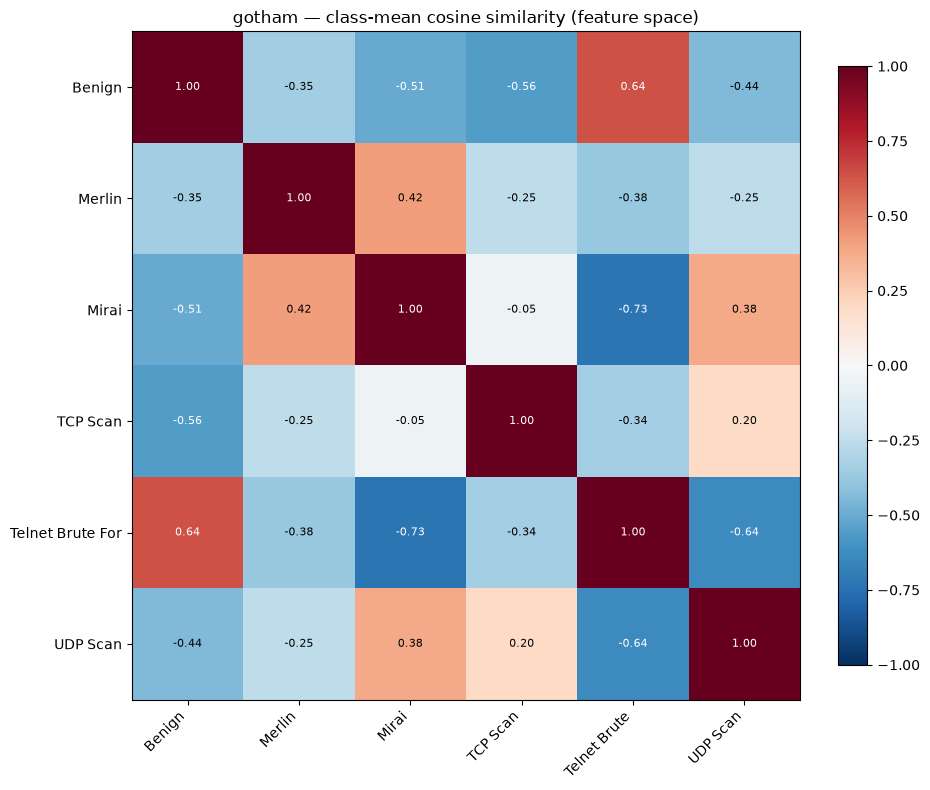

saved diagnostic_gotham_class_similarity.png


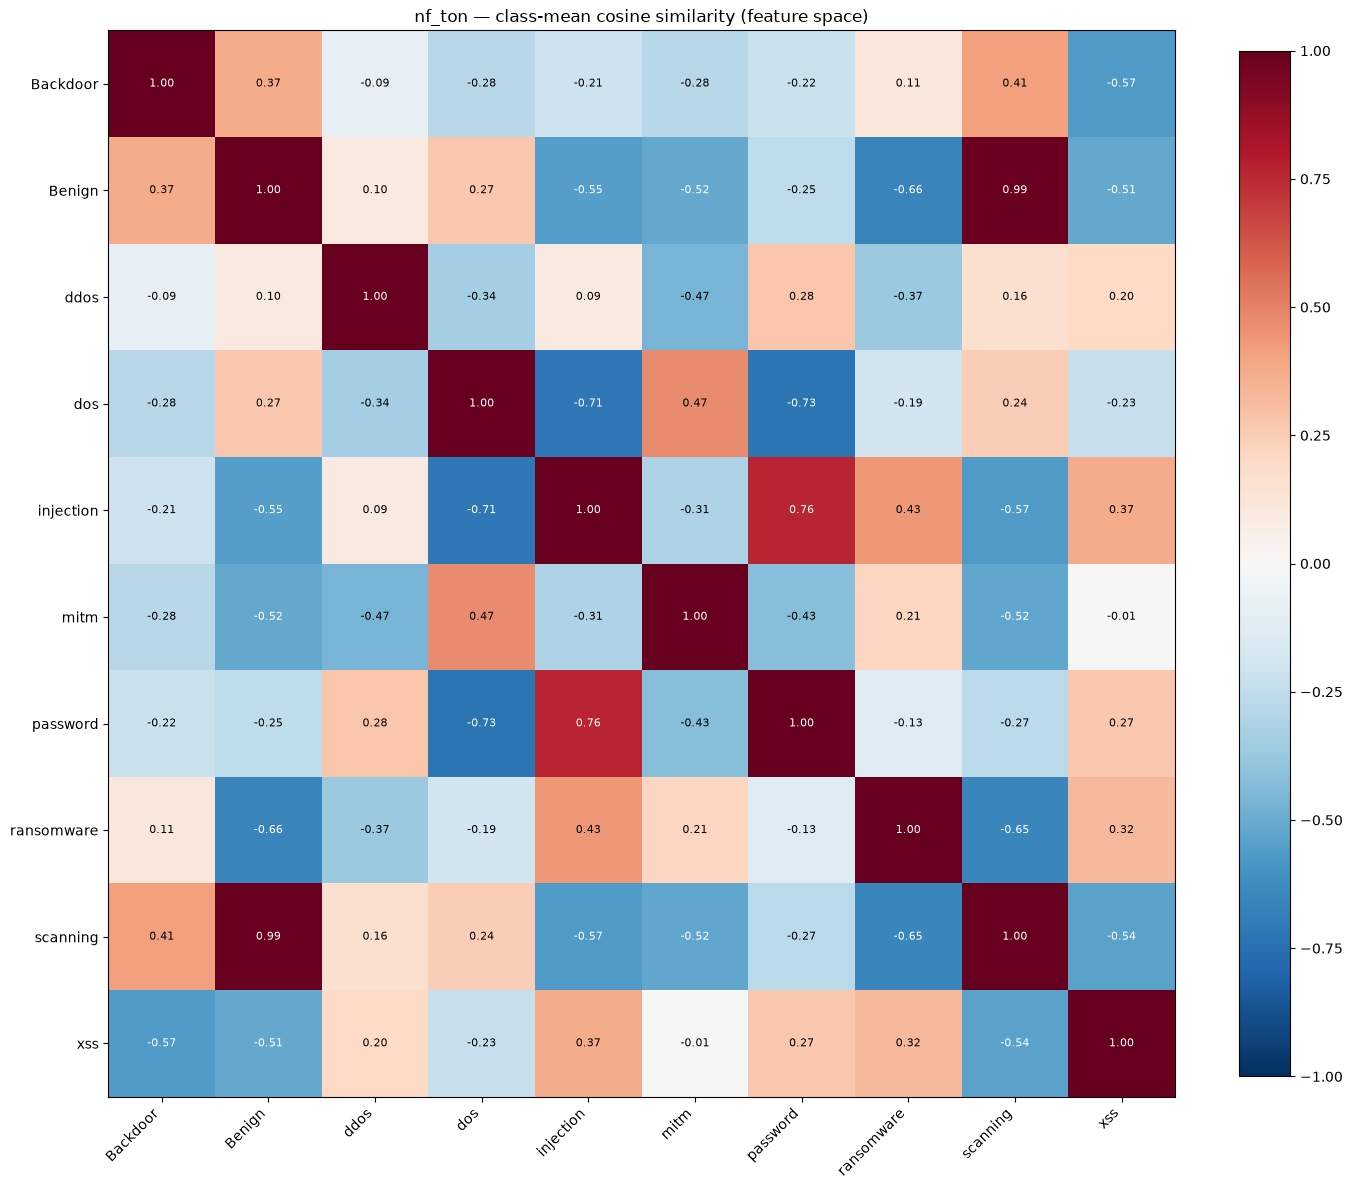

saved diagnostic_nf_ton_class_similarity.png


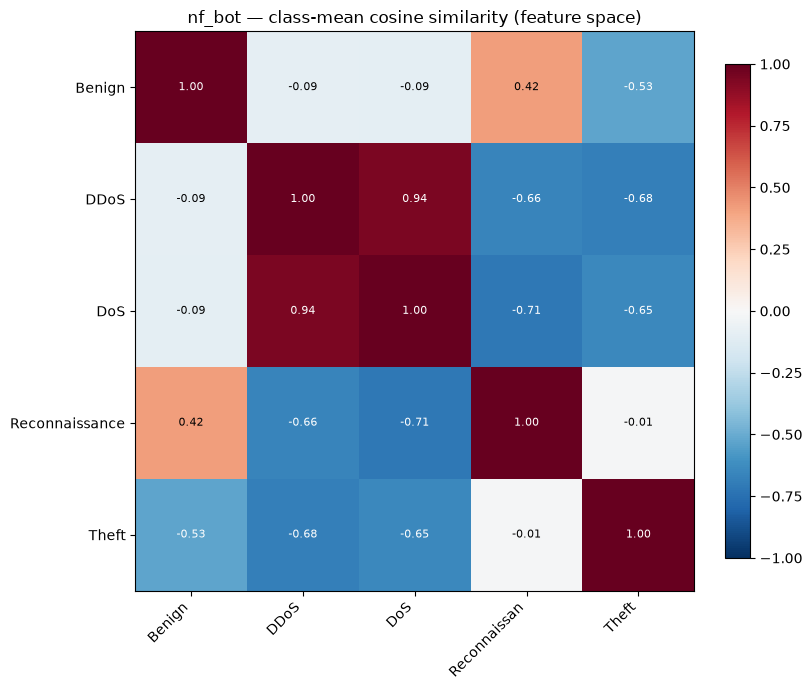

saved diagnostic_nf_bot_class_similarity.png


In [5]:
try:
    import matplotlib
    %matplotlib inline
    import matplotlib.pyplot as plt

    for ds_name, cfg in DATASETS.items():
        if ds_name not in DIAGNOSTIC: continue
        splits = load_splits(cfg['dir'])
        merge_fn = cfg['label_merge_fn']
        labels = [dominant_label(g, ATTACK_THRESHOLD, merge_fn) for g in splits['train']]
        per_class_edges, _ = per_class_edge_agg(splits['train'], labels)
        classes, sim = class_pair_similarity(per_class_edges)

        fig, ax = plt.subplots(figsize=(1.2*len(classes)+2, 1.0*len(classes)+2))
        im = ax.imshow(sim, cmap='RdBu_r', vmin=-1, vmax=1)
        ax.set_xticks(range(len(classes)))
        ax.set_yticks(range(len(classes)))
        ax.set_xticklabels([c[:12] for c in classes], rotation=45, ha='right')
        ax.set_yticklabels([c[:16] for c in classes])
        for i in range(len(classes)):
            for j in range(len(classes)):
                ax.text(j, i, f"{sim[i,j]:.2f}", ha='center', va='center',
                        color='white' if abs(sim[i,j])>0.5 else 'black', fontsize=8)
        ax.set_title(f"{ds_name} — class-mean cosine similarity (feature space)")
        plt.colorbar(im, ax=ax, fraction=0.04)
        plt.tight_layout()
        out = f'diagnostic_{ds_name}_class_similarity.png'
        plt.savefig(out, dpi=120, bbox_inches='tight')
        plt.show()
        plt.close(fig)
        print(f"saved {out}")
        del splits; gc.collect()
except Exception as e:
    print(f"[skip plotting] {e}")

In [6]:
# ============================================================================
# Cell 6 — Graph-topology and temporal diagnostics
# ============================================================================
import torch
from collections import Counter, defaultdict
import numpy as np

def graph_topology_features(g):
    """Return per-graph topology fingerprint as a dict."""
    ei = g.edge_index.cpu().numpy()
    src, dst = ei[0], ei[1]
    n_edges = len(src)
    if n_edges == 0:
        return dict(n_edges=0, n_unique_src=0, n_unique_dst=0, n_nodes=0,
                    max_out_deg=0, max_in_deg=0, out_deg_gini=0.0,
                    in_deg_gini=0.0, src_concentration=0.0,
                    dst_concentration=0.0, mean_out_deg=0.0, mean_in_deg=0.0,
                    density=0.0)

    # Unique node counts
    n_unique_src = int(len(np.unique(src)))
    n_unique_dst = int(len(np.unique(dst)))
    nodes_all = np.concatenate([src, dst])
    n_nodes = int(len(np.unique(nodes_all)))

    # Degree distributions
    out_deg = np.bincount(src)          # out-degree of each node as src
    in_deg  = np.bincount(dst)          # in-degree of each node as dst
    max_out = int(out_deg.max()) if len(out_deg) else 0
    max_in  = int(in_deg.max()) if len(in_deg) else 0
    mean_out = float(out_deg.mean()) if len(out_deg) else 0.0
    mean_in  = float(in_deg.mean()) if len(in_deg) else 0.0

    # Gini coefficient (concentration)
    def gini(x):
        x = np.sort(np.asarray(x, dtype=float))
        if len(x) == 0 or x.sum() == 0:
            return 0.0
        n = len(x); idx = np.arange(1, n + 1)
        return float((2 * (idx * x).sum() / (n * x.sum())) - (n + 1) / n)

    # Fraction of edges from top-1 source / to top-1 destination
    src_conc = float(np.bincount(src).max() / n_edges)
    dst_conc = float(np.bincount(dst).max() / n_edges)

    # Graph density (edges / possible directed edges)
    density = n_edges / max(n_nodes * (n_nodes - 1), 1)

    return dict(
        n_edges=n_edges, n_unique_src=n_unique_src, n_unique_dst=n_unique_dst,
        n_nodes=n_nodes, max_out_deg=max_out, max_in_deg=max_in,
        out_deg_gini=gini(out_deg), in_deg_gini=gini(in_deg),
        src_concentration=src_conc, dst_concentration=dst_conc,
        mean_out_deg=mean_out, mean_in_deg=mean_in,
        density=density,
    )


def per_class_topology(graphs, labels):
    """Aggregate topology features per class."""
    buckets = defaultdict(list)
    for g, l in zip(graphs, labels):
        buckets[l].append(graph_topology_features(g))
    out = {}
    for c, feats in buckets.items():
        keys = feats[0].keys()
        out[c] = {k: np.array([f[k] for f in feats], dtype=float) for k in keys}
    return out


def topo_class_means(topo):
    """Per-class mean of each topology feature."""
    classes = sorted(topo)
    feature_names = list(topo[classes[0]].keys())
    means = {}
    for c in classes:
        means[c] = np.array([topo[c][k].mean() for k in feature_names])
    return classes, feature_names, means


def topo_similarity(topo):
    """Cosine similarity between class-mean topology fingerprints."""
    classes, fnames, means = topo_class_means(topo)
    M = np.stack([means[c] for c in classes])
    # Standardize across classes (z-score per feature)
    Ms = (M - M.mean(0)) / (M.std(0) + 1e-8)
    from sklearn.metrics import pairwise_distances
    sim = 1 - pairwise_distances(Ms, metric='cosine')
    return classes, fnames, sim, means


def temporal_fingerprint(graphs):
    """Return timestamp array for a list of graphs."""
    return np.array([float(getattr(g, 'window_start_unix', 0.0)) for g in graphs])


# ============================================================================
# Run the diagnostic for each dataset
# ============================================================================

TOPO_DIAG = {}

for ds_name, cfg in DATASETS.items():
    if not os.path.isdir(cfg['dir']):
        print(f"[skip] {ds_name}"); continue

    print(f"\n{'#'*100}\n# {ds_name.upper()} — TOPOLOGY + TEMPORAL\n{'#'*100}")

    splits = load_splits(cfg['dir'])
    merge_fn = cfg['label_merge_fn']
    thr = ATTACK_THRESHOLD

    all_graphs = splits['train'] + splits['val'] + splits['test']
    labels     = [dominant_label(g, thr, merge_fn) for g in all_graphs]
    times      = temporal_fingerprint(all_graphs)

    # ---------- [A] Per-class topology fingerprint ----------
    topo = per_class_topology(all_graphs, labels)
    classes, fnames, means = topo_class_means(topo)

    print("\n[A] Per-class topology fingerprint (mean over graphs)")
    hdr = '  ' + f"{'class':<22}" + ''.join(f"{n[:12]:>13}" for n in fnames)
    print(hdr)
    for c in classes:
        m = means[c]
        print(f"  {c[:22]:<22}" + ''.join(f"{m[i]:>13.3f}" for i in range(len(m))))

    # ---------- [B] DoS vs DDoS direct comparison ----------
    print("\n[B] DoS vs DDoS topology (single-source vs multi-source signature)")
    for c in classes:
        if 'DoS' in c or 'ddos' in c.lower():
            m = means[c]
            i_src = fnames.index('n_unique_src')
            i_dst = fnames.index('n_unique_dst')
            i_maxin = fnames.index('max_in_deg')
            i_conc = fnames.index('src_concentration')
            print(f"  {c:<16}  unique_src={m[i_src]:>7.2f}  "
                  f"unique_dst={m[i_dst]:>7.2f}  "
                  f"max_in_deg={m[i_maxin]:>7.2f}  "
                  f"src_conc={m[i_conc]:>6.3f}")

    # ---------- [C] Topology similarity matrix ----------
    cls2, _, sim, _ = topo_similarity(topo)
    print("\n[C] Topology-space cosine similarity")
    short = [c[:10] for c in cls2]
    print('  ' + ' '*14 + ''.join(f"{n:>11}" for n in short))
    for i, c in enumerate(cls2):
        print(f"  {c[:14]:<14}" + ''.join(f"{sim[i,j]:>11.3f}" for j in range(len(cls2))))

    # Benign's nearest attack in topology space
    if 'Benign' in cls2:
        bi = cls2.index('Benign')
        near = sorted([(cls2[j], sim[bi, j]) for j in range(len(cls2)) if j != bi],
                      key=lambda x: -x[1])
        print(f"\n  Nearest attack to Benign (topology) : {near[0][0]} ({near[0][1]:.3f})")
        print(f"  Farthest attack from Benign          : {near[-1][0]} ({near[-1][1]:.3f})")

    # ---------- [D] Temporal distribution ----------
    print("\n[D] Temporal concentration per class")
    print(f"  {'class':<22} {'n':>6} {'span_h':>8} {'time_std_h':>11} "
          f"{'distinct_hours':>15}")
    for c in sorted(set(labels)):
        m = np.array(labels) == c
        ts = times[m]
        if len(ts) < 2: continue
        span_h = (ts.max() - ts.min()) / 3600.0
        std_h  = ts.std() / 3600.0
        hours  = len(np.unique((ts // 3600).astype(int)))
        print(f"  {c[:22]:<22} {m.sum():>6} {span_h:>8.1f} {std_h:>11.2f} "
              f"{hours:>15}")

    TOPO_DIAG[ds_name] = {
        'class_topology_means': {c: dict(zip(fnames, means[c].tolist()))
                                 for c in classes},
        'topology_similarity_matrix': {classes[i]: sim[i].tolist()
                                       for i in range(len(classes))},
        'topology_nearest_to_benign': near[0][0] if 'Benign' in cls2 else None,
        'topology_nearest_score':    near[0][1] if 'Benign' in cls2 else None,
    }
    del splits; gc.collect()

with open('dataset_topology_diagnostic.json', 'w') as f:
    json.dump(TOPO_DIAG, f, indent=2)
print("\nSaved dataset_topology_diagnostic.json")


####################################################################################################
# GOTHAM — TOPOLOGY + TEMPORAL
####################################################################################################

[A] Per-class topology fingerprint (mean over graphs)
  class                       n_edges n_unique_src n_unique_dst      n_nodes  max_out_deg   max_in_deg out_deg_gini  in_deg_gini src_concentr dst_concentr mean_out_deg  mean_in_deg      density
  Benign                       63.117       18.427       18.486       36.392       12.759       12.768        0.399        0.638        0.273        0.273        2.365        1.379        0.107
  CoAP Amplification            3.000        3.000        2.000        5.000        1.000        2.000        0.250        0.667        0.333        0.667        0.750        0.600        0.150
  Merlin                      209.327        8.288        8.296       16.429      118.801      118.380        0.395        0.618 